# Emoji provider classification: first CNN submission

This notebook adapts the instructor's **Random submission** notebook and keeps its five steps. It fixes image loading, trains a small convolutional neural network from scratch, and writes the provider names expected by Kaggle.

**Colab:** select **Runtime → Change runtime type → T4 GPU**, upload `2-computer-vision-2026-b-sc-aidams-final-proj.zip` into the Files panel, then **Runtime → Run all**. If GPU access is unavailable, the notebook falls back to CPU. Keep the tab open until Step 5 finishes. Download `submission.csv` from the `emoji_outputs` folder and upload it to the competition.

**VS Code:** install the Python and Jupyter extensions. Create a Python 3.13 environment with `uv venv .venv --python 3.13`, then run `uv pip install --python .venv/bin/python ipykernel torch==2.8.0 numpy==2.2.6 pandas==2.3.1 scikit-learn==1.7.1 matplotlib==3.10.5 pillow==11.3.0`. On Windows, the Python path is `.venv/Scripts/python.exe`. Select that environment as the notebook kernel. Keep the ZIP beside the notebook or in Downloads, or set `ZIP_PATH` below. Choose **Run All**.

The setup cell installs missing packages only so Colab keeps its working GPU build of PyTorch. Fresh installations use the versions above. Every run records the actual versions in `run_metadata.json` and `requirements-used.txt`.

**Course requirement:** each student must run their copy in Colab and submit a CSV at least once. This notebook is a completed adaptation of the supplied five-step starter. The written report is for the students to write themselves.

## STEP 1: Install and import libraries


In [3]:
import importlib.metadata
import subprocess
import sys

REFERENCE_VERSIONS = {
    "torch": "2.8.0",
    "numpy": "2.2.6",
    "pandas": "2.3.1",
    "scikit-learn": "1.7.1",
    "matplotlib": "3.10.5",
    "pillow": "11.3.0",
}
missing_packages: list[str] = []
for package, version in REFERENCE_VERSIONS.items():
    try:
        importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        missing_packages.append(f"{package}=={version}")
if missing_packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_packages]
    )
print("Python:", sys.version.split()[0])
print({name: importlib.metadata.version(name) for name in REFERENCE_VERSIONS})

Python: 3.13.15
{'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'pillow': '11.3.0'}


In [4]:
import hashlib
import json
import os
import random
import time
import zipfile
from collections import Counter
from pathlib import Path
from typing import TypedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from numpy.typing import NDArray
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.optim import Optimizer
from torch.utils.data import DataLoader, TensorDataset

# Change this only if automatic ZIP discovery cannot find your dataset.
ZIP_PATH: str | None = None
ZIP_NAME = "2-computer-vision-2026-b-sc-aidams-final-proj.zip"
SEED = 42
IMAGE_SIZE = 96
BATCH_SIZE = 64
MAX_EPOCHS = 20
PATIENCE = 4
LEARNING_RATE = 0.001
# For a short installation check only. A smoke run is NOT a competition model.
SMOKE_TEST = os.environ.get("EMOJI_SMOKE_TEST", "0") == "1"
OUTPUT_DIR = Path(os.environ.get("EMOJI_OUTPUT_DIR", "emoji_outputs"))
DATA_DIR = Path("emoji_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(min(4, os.cpu_count() or 1))
print("Training device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))
if SMOKE_TEST:
    print("SMOKE TEST: two short epochs; output will be smoke_submission.csv")

Training device: cuda
Tesla T4


## STEP 2: Import and parse the data

Labels come from `train_labels.csv`. IDs remain strings, including leading zeros. Training images are matched to their label by ID, never by an assumed row position. The ZIP is extracted into a dedicated folder. No Kaggle credentials are needed.


In [5]:
def find_zip(configured_path: str | None) -> Path:
    if configured_path:
        candidate = Path(configured_path).expanduser()
        if not candidate.is_file():
            raise FileNotFoundError(f"ZIP_PATH does not exist: {candidate}")
        return candidate
    candidates = [
        Path("/content") / ZIP_NAME,
        Path.cwd() / ZIP_NAME,
        Path.home() / "Downloads" / ZIP_NAME,
    ]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Upload {ZIP_NAME} to Colab's Files panel, put it beside this notebook, "
        "or set ZIP_PATH in Step 1."
    )


def extract_data(archive_path: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            if not (root / member.filename).resolve().is_relative_to(root):
                raise ValueError(f"Unsafe ZIP path: {member.filename}")
        archive.extractall(root)


archive_path = find_zip(ZIP_PATH)
extract_data(archive_path, DATA_DIR)
labels = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"Id": str, "Label": str})
assert labels.columns.tolist() == ["Id", "Label"], "Unexpected label CSV columns"
assert labels.notna().all().all(), "Missing ID or label"
assert labels["Id"].is_unique, "Duplicate IDs in label CSV"
train_files = {path.stem: path for path in (DATA_DIR / "train").glob("*.png")}
test_files = {path.stem: path for path in (DATA_DIR / "test").glob("*.png")}
assert train_files and test_files, "Expected PNG files in train/ and test/"
assert set(labels["Id"]) == set(train_files), "Training IDs and image files differ"
assert set(train_files).isdisjoint(test_files), "Train and test IDs overlap"
labels = labels.sort_values("Id").reset_index(drop=True)
train_ids = labels["Id"].tolist()
test_ids = sorted(test_files)
class_names = sorted(labels["Label"].unique().tolist())
class_to_index = {name: index for index, name in enumerate(class_names)}
y = labels["Label"].map(class_to_index).to_numpy(dtype=np.int64)
print(f"{len(train_ids):,} training images; {len(test_ids):,} test images")
print("Providers:", class_names)
display(labels.head())

9,879 training images; 9,879 test images
Providers: ['apple', 'facebook', 'google', 'messenger', 'mozilla', 'samsung', 'whatsapp']


,Id,Label
0,00001,samsung
1,00002,apple
2,00003,facebook
3,00004,facebook
4,00005,google


The model sees **RGB colour, 96 × 96 pixels**. Transparent pixels are composited onto white. Images are resized without changing their aspect ratio, then centred on a white square. This fixes the starter's unequal image shapes and keeps colour and shading cues. No crops, rotations, or colour changes are applied for this first experiment.

Images are stored in memory as unsigned bytes and converted to floats per batch. This uses less memory than keeping the whole dataset as float tensors.


In [6]:
def load_rgb(path: Path, size: int = IMAGE_SIZE) -> NDArray[np.uint8]:
    with Image.open(path) as original:
        rgba = original.convert("RGBA")
        white = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
        rgb = Image.alpha_composite(white, rgba).convert("RGB")
        fitted = ImageOps.contain(rgb, (size, size), Image.Resampling.LANCZOS)
        square = Image.new("RGB", (size, size), (255, 255, 255))
        square.paste(fitted, ((size - fitted.width) // 2, (size - fitted.height) // 2))
        return np.asarray(square, dtype=np.uint8).copy()


def load_images(paths: list[Path]) -> tuple[torch.Tensor, list[str]]:
    pixels = np.empty((len(paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    hashes: list[str] = []
    for index, path in enumerate(paths):
        pixels[index] = load_rgb(path)
        hashes.append(hashlib.sha256(pixels[index].tobytes()).hexdigest())
        if (index + 1) % 2000 == 0:
            print(f"Loaded {index + 1:,}/{len(paths):,} images", flush=True)
    return torch.from_numpy(pixels).permute(0, 3, 1, 2).contiguous(), hashes


train_pixels, train_hashes = load_images(
    [train_files[image_id] for image_id in train_ids]
)
assert train_pixels.shape == (len(labels), 3, IMAGE_SIZE, IMAGE_SIZE)
print("Training tensor:", tuple(train_pixels.shape), train_pixels.dtype)

Loaded 2,000/9,879 images
Loaded 4,000/9,879 images
Loaded 6,000/9,879 images
Loaded 8,000/9,879 images
Training tensor: (9879, 3, 96, 96) torch.uint8


## STEP 3: Data analysis

Check the provider counts and example images before training. Providers may have unequal numbers of examples, so the validation set should preserve their proportions as closely as possible. Identical preprocessed images are placed in the same split to avoid exact duplicates leaking across training and validation. Similar images that are not identical may still cross the split; that is a limitation of this first baseline.


,images
Label,
apple,1924
facebook,1667
google,1877
messenger,580
mozilla,397
samsung,1790
whatsapp,1644


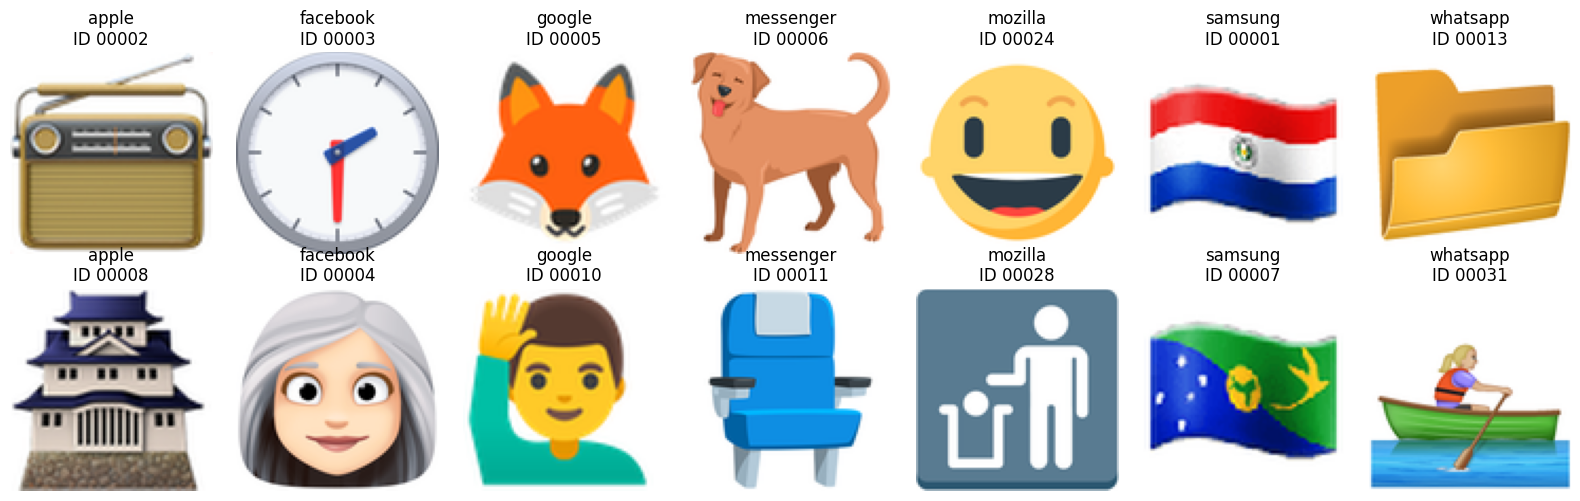

Repeated preprocessed images beyond the first copy: 158
Identical-image groups with more than one provider label: 0
Train: 7,900; validation: 1,979
Always predict apple: 19.61% validation accuracy


,provider,train,validation
0,apple,1536,388
1,facebook,1299,368
2,google,1513,364
3,messenger,459,121
4,mozilla,315,82
5,samsung,1429,361
6,whatsapp,1349,295


In [7]:
provider_counts = labels["Label"].value_counts().reindex(class_names)
display(provider_counts.rename("images").to_frame())
fig, axes = plt.subplots(2, len(class_names), figsize=(16, 5))
for column, provider in enumerate(class_names):
    examples = np.flatnonzero(labels["Label"].to_numpy() == provider)[:2]
    for row, index in enumerate(examples):
        axes[row, column].imshow(train_pixels[index].permute(1, 2, 0).numpy())
        axes[row, column].set_title(f"{provider}\nID {train_ids[index]}")
        axes[row, column].axis("off")
fig.tight_layout()
plt.show()

group_counts = Counter(train_hashes)
duplicate_images = sum(count - 1 for count in group_counts.values())
conflicting_groups = (
    labels.assign(pixel_hash=train_hashes).groupby("pixel_hash")["Label"].nunique() > 1
).sum()
print(f"Repeated preprocessed images beyond the first copy: {duplicate_images}")
print(f"Identical-image groups with more than one provider label: {conflicting_groups}")

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(np.zeros(len(y)), y, groups=train_hashes))
assert set(np.asarray(train_hashes)[train_idx]).isdisjoint(
    np.asarray(train_hashes)[val_idx]
), "A duplicate image crossed the split"
assert set(y[train_idx]) == set(y[val_idx]) == set(range(len(class_names)))
if SMOKE_TEST:
    train_idx = np.concatenate(
        [train_idx[y[train_idx] == c][:10] for c in range(len(class_names))]
    )
    val_idx = np.concatenate(
        [val_idx[y[val_idx] == c][:3] for c in range(len(class_names))]
    )

majority_class = int(np.bincount(y[train_idx]).argmax())
majority_accuracy = float(np.mean(y[val_idx] == majority_class))
print(f"Train: {len(train_idx):,}; validation: {len(val_idx):,}")
print(
    f"Always predict {class_names[majority_class]}: {majority_accuracy:.2%} validation accuracy"
)
split_table = pd.DataFrame(
    {
        "provider": class_names,
        "train": np.bincount(y[train_idx], minlength=len(class_names)),
        "validation": np.bincount(y[val_idx], minlength=len(class_names)),
    }
)
display(split_table)
# Preserve the exact split so later models can be compared fairly.
split_manifest = labels.copy()
split_manifest["split"] = "unused_smoke" if SMOKE_TEST else "train"
split_manifest.loc[train_idx, "split"] = "train"
split_manifest.loc[val_idx, "split"] = "validation"
split_manifest.to_csv(OUTPUT_DIR / "split.csv", index=False)

## STEP 4: Train a model on the training dataset

Three blocks learn increasingly abstract image features. Each block has a 3 × 3 convolution, ReLU activation, and 2 × 2 max pooling. Global average pooling produces one value per feature channel. Dropout discourages reliance on a few channels, and the final linear layer produces one score per provider.

Cross-entropy trains the scores against the correct provider. Adam uses a learning rate of 0.001. We train for at most 20 epochs and stop after four epochs without a lower validation loss. The checkpoint with the lowest validation loss makes the submission. This first run keeps its validation holdout; it does not refit on all labelled images. Fixed seeds help comparisons, but GPU and operating-system differences can still change the results.


In [8]:
class EmojiCNN(nn.Module):
    def __init__(self, number_of_classes: int) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.25), nn.Linear(128, number_of_classes)
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(images))


def make_loader(indices: NDArray[np.int64], shuffle: bool) -> DataLoader:
    dataset = TensorDataset(train_pixels[indices], torch.from_numpy(y[indices]))
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,  # Works in Colab and Windows/macOS notebook kernels.
        generator=torch.Generator().manual_seed(SEED),
        pin_memory=DEVICE.type == "cuda",
    )


train_loader = make_loader(train_idx, shuffle=True)
val_loader = make_loader(val_idx, shuffle=False)
model = EmojiCNN(len(class_names)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

EmojiCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=128, out_features=7, bias=True)
  )
)
Trainable parameters: 94,151


In [9]:
def run_epoch(
    network: nn.Module,
    loader: DataLoader,
    training_optimizer: Optimizer | None = None,
) -> tuple[float, float]:
    training = training_optimizer is not None
    network.train(training)
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images = images.to(DEVICE, dtype=torch.float32) / 255.0
            targets = targets.to(DEVICE)
            if training_optimizer is not None:
                training_optimizer.zero_grad(set_to_none=True)
            scores = network(images)
            loss = criterion(scores, targets)
            if training_optimizer is not None:
                loss.backward()
                training_optimizer.step()
            count = targets.size(0)
            total_loss += loss.item() * count
            correct += int((scores.argmax(dim=1) == targets).sum().item())
            total += count
    return total_loss / total, correct / total


class EpochResult(TypedDict):
    epoch: int
    train_loss: float
    val_loss: float
    train_accuracy: float
    val_accuracy: float
    seconds: float


history: list[EpochResult] = []
best_loss = float("inf")
best_epoch = 0
stale_epochs = 0
checkpoint_path = OUTPUT_DIR / "best_model.pt"
training_started = time.perf_counter()
for epoch in range(1, (2 if SMOKE_TEST else MAX_EPOCHS) + 1):
    epoch_started = time.perf_counter()
    train_loss, train_accuracy = run_epoch(model, train_loader, optimizer)
    val_loss, val_accuracy = run_epoch(model, val_loader)
    record: EpochResult = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "seconds": time.perf_counter() - epoch_started,
    }
    history.append(record)
    pd.DataFrame(history).to_csv(OUTPUT_DIR / "history.csv", index=False)
    print(
        f"Epoch {epoch:02d} | train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
        f"validation loss {val_loss:.4f}, accuracy {val_accuracy:.2%} | "
        f"{record['seconds']:.1f}s",
        flush=True,
    )
    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch
        stale_epochs = 0
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": class_names,
                "image_size": IMAGE_SIZE,
                "epoch": epoch,
                "validation_loss": val_loss,
                "validation_accuracy": val_accuracy,
            },
            checkpoint_path,
        )
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print(f"Early stopping. Restoring epoch {best_epoch}.")
            break
training_seconds = time.perf_counter() - training_started
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(
    f"Restored epoch {best_epoch}; training took {training_seconds / 60:.1f} minutes."
)

Epoch 01 | train loss 1.8398, accuracy 20.25% | validation loss 1.8261, accuracy 23.09% | 4.0s
Epoch 02 | train loss 1.7904, accuracy 25.13% | validation loss 1.7710, accuracy 25.87% | 2.8s
Epoch 03 | train loss 1.7118, accuracy 30.22% | validation loss 1.6476, accuracy 34.31% | 2.8s
Epoch 04 | train loss 1.5967, accuracy 37.85% | validation loss 1.5361, accuracy 40.02% | 2.8s
Epoch 05 | train loss 1.4593, accuracy 45.65% | validation loss 1.3690, accuracy 52.50% | 2.8s
Epoch 06 | train loss 1.3210, accuracy 51.54% | validation loss 1.3572, accuracy 45.33% | 2.8s
Epoch 07 | train loss 1.1878, accuracy 56.77% | validation loss 1.2880, accuracy 49.97% | 2.9s
Epoch 08 | train loss 1.1264, accuracy 58.95% | validation loss 1.0696, accuracy 63.92% | 2.8s
Epoch 09 | train loss 1.0494, accuracy 62.38% | validation loss 1.0808, accuracy 62.41% | 2.8s
Epoch 10 | train loss 1.0120, accuracy 64.09% | validation loss 0.9735, accuracy 66.25% | 2.8s
Epoch 11 | train loss 0.9436, accuracy 66.43% | va

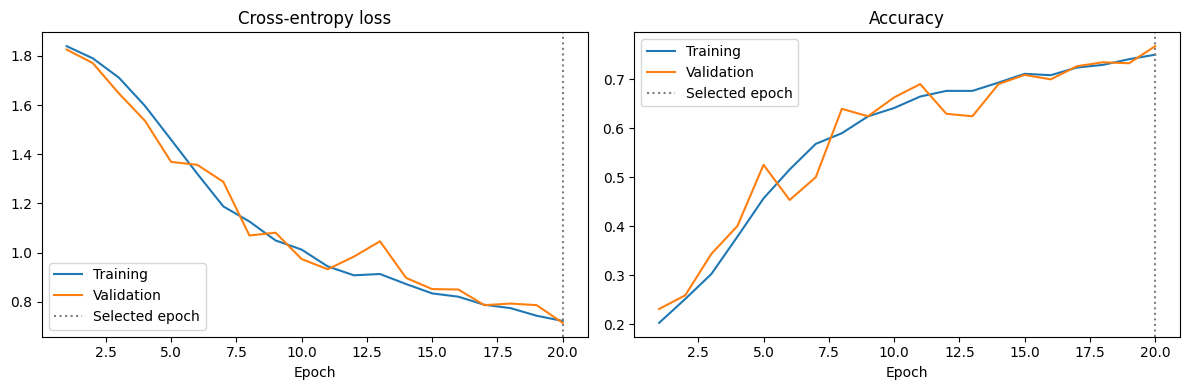

Selected checkpoint validation accuracy: 76.71%
Majority-class baseline: 19.61%
              precision    recall  f1-score   support

       apple       0.76      0.77      0.76       388
    facebook       0.73      0.69      0.71       368
      google       0.85      0.94      0.89       364
   messenger       0.68      0.42      0.52       121
     mozilla       0.75      0.74      0.75        82
     samsung       0.79      0.75      0.77       361
    whatsapp       0.72      0.82      0.77       295

    accuracy                           0.77      1979
   macro avg       0.75      0.73      0.74      1979
weighted avg       0.76      0.77      0.76      1979



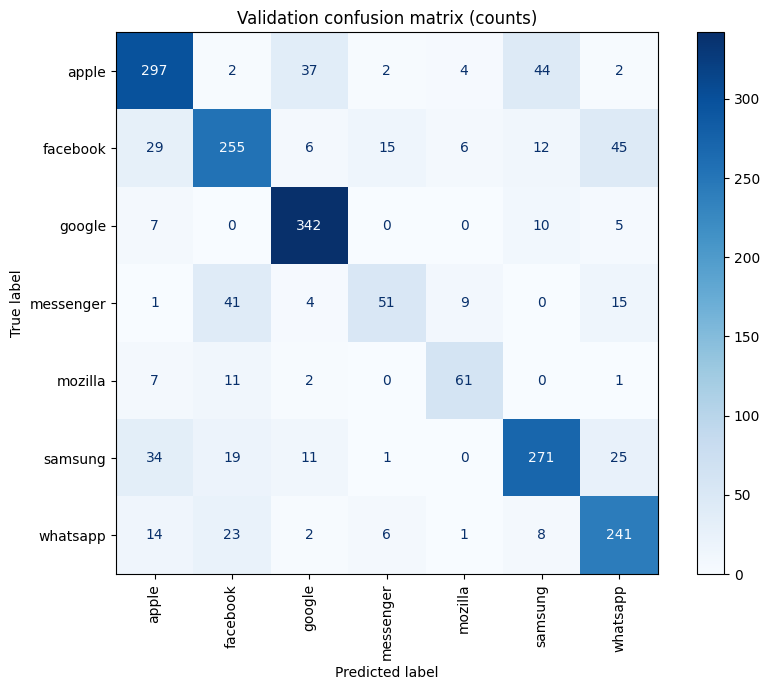

In [10]:
def predict(network: nn.Module, loader: DataLoader) -> NDArray[np.int64]:
    network.eval()
    predicted: list[NDArray[np.int64]] = []
    with torch.inference_mode():
        for batch in loader:
            images = batch[0].to(DEVICE, dtype=torch.float32) / 255.0
            predicted.append(network(images).argmax(dim=1).cpu().numpy())
    return np.concatenate(predicted).astype(np.int64)


history_frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for prefix, name in [("train", "Training"), ("val", "Validation")]:
    axes[0].plot(history_frame["epoch"], history_frame[f"{prefix}_loss"], label=name)
    axes[1].plot(
        history_frame["epoch"], history_frame[f"{prefix}_accuracy"], label=name
    )
for axis, title in zip(axes, ["Cross-entropy loss", "Accuracy"], strict=True):
    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.axvline(best_epoch, color="grey", linestyle=":", label="Selected epoch")
    axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150)
plt.show()

val_predictions = predict(model, val_loader)
validation_accuracy = float(np.mean(val_predictions == y[val_idx]))
print(f"Selected checkpoint validation accuracy: {validation_accuracy:.2%}")
print(f"Majority-class baseline: {majority_accuracy:.2%}")
print(
    classification_report(
        y[val_idx],
        val_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division="warn",
    )
)
fig, axis = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y[val_idx],
    val_predictions,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    cmap="Blues",
    ax=axis,
    xticks_rotation="vertical",
)
axis.set_title("Validation confusion matrix (counts)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## STEP 5: Make predictions and export the submission

The supplied ZIP contains no sample submission. The instructor's starter writes the two columns `Id,Label`, so we use those exact column names. Test IDs come from the filenames, such as `10001`. The output contains provider names, not internal class numbers. If you later receive a sample submission, use its ID order as the authority.

The model checkpoint, label mapping, split, learning curves, training history, and run settings are saved beside the CSV. The checks below reject missing IDs, duplicate IDs, and labels outside the training classes. Validation accuracy is measured on held-out training data; it is not the Kaggle leaderboard score.


In [11]:
test_pixels, _ = load_images([test_files[image_id] for image_id in test_ids])
test_loader = DataLoader(
    TensorDataset(test_pixels), batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
predicted_indices = predict(model, test_loader)
submission = pd.DataFrame(
    {
        "Id": test_ids,
        "Label": [class_names[index] for index in predicted_indices],
    }
)
assert submission.columns.tolist() == ["Id", "Label"]
assert len(submission) == len(test_files)
assert submission["Id"].is_unique
assert submission["Id"].tolist() == test_ids
assert set(submission["Id"]) == set(test_files)
assert submission.notna().all().all()
assert set(submission["Label"]).issubset(class_names)
submission_path = OUTPUT_DIR / (
    "smoke_submission.csv" if SMOKE_TEST else "submission.csv"
)
submission.to_csv(submission_path, index=False)
roundtrip = pd.read_csv(submission_path, dtype=str)
pd.testing.assert_frame_equal(submission, roundtrip)
display(submission.head(10))
print(f"Saved {len(submission):,} predictions to {submission_path.resolve()}")
print(submission["Label"].value_counts().to_string())

Loaded 2,000/9,879 images
Loaded 4,000/9,879 images
Loaded 6,000/9,879 images
Loaded 8,000/9,879 images


,Id,Label
0,10001,google
1,10002,facebook
2,10003,samsung
3,10004,whatsapp
4,10005,samsung
5,10006,samsung
6,10007,messenger
7,10008,apple
8,10009,apple
9,10010,samsung


Saved 9,879 predictions to /content/emoji_outputs/submission.csv
Label
google       2155
apple        1863
whatsapp     1773
samsung      1643
facebook     1624
mozilla       419
messenger     402


In [12]:
versions = {name: importlib.metadata.version(name) for name in REFERENCE_VERSIONS}
metadata = {
    "model": "EmojiCNN: RGB96, channels32/64/128, global average pooling, dropout0.25",
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "maximum_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "best_epoch": best_epoch,
    "epochs_run": len(history),
    "validation_accuracy": validation_accuracy,
    "validation_loss": best_loss,
    "majority_baseline_accuracy": majority_accuracy,
    "split": "First fold of StratifiedGroupKFold(5, shuffle=True, random_state=42); groups are SHA256 of preprocessed RGB pixels",
    "training_examples": len(train_idx),
    "validation_examples": len(val_idx),
    "test_examples": len(test_ids),
    "duplicate_images": duplicate_images,
    "conflicting_duplicate_groups": int(conflicting_groups),
    "training_seconds": training_seconds,
    "device": str(DEVICE),
    "python_version": sys.version,
    "package_versions": versions,
    "class_names": class_names,
    "smoke_test": SMOKE_TEST,
    "ai_assistance": "OpenAI Codex generated and debugged this notebook; user prompts are recorded below. The students write the report.",
}
(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "label_mapping.json").write_text(
    json.dumps(class_to_index, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "requirements-used.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in versions.items()) + "\n",
    encoding="utf-8",
)
print("Saved files:")
for output in sorted(OUTPUT_DIR.iterdir()):
    if output.is_file():
        print(f"  {output.name}: {output.stat().st_size:,} bytes")
if SMOKE_TEST:
    print(
        "SMOKE TEST ONLY. Set EMOJI_SMOKE_TEST=0 and rerun all cells for the real submission."
    )
else:
    print("Download submission.csv from the Files panel and submit it on Kaggle.")

Saved files:
  best_model.pt: 380,855 bytes
  confusion_matrix.png: 84,931 bytes
  history.csv: 1,994 bytes
  label_mapping.json: 115 bytes
  learning_curves.png: 98,303 bytes
  requirements-used.txt: 101 bytes
  run_metadata.json: 1,274 bytes
  split.csv: 206,236 bytes
  submission.csv: 136,635 bytes
Download submission.csv from the Files panel and submit it on Kaggle.


### AI usage disclosure and prompt log

OpenAI Codex generated and debugged the data checks, image preprocessing, model, training loop, validation plots, and export code in this notebook. The instructor's supplied notebook provided the five-step structure and submission column names. No pretrained weights, external images, or test labels are used. The students must review and understand the code, keep an accurate record of changes, and write their report themselves. This notebook does not contain an AI-written project report.

User prompt 1, exact request before the pasted course email:
> look at this and make a suggestion for a first submissions off of an ipynb that I could run on colab or vs code locally :

The user then supplied the instructor's full email as context. It permits AI assistance with code and model understanding, asks students to disclose AI use and prompts, and asks students to write the report themselves. The initial assistant suggestion was an RGB96 CNN with 32/64/128 filters, global average pooling, Adam at 0.001, and up to 20 epochs with early stopping.

User prompt 2, exact request:
> ok cool take control of my chrome and make it happen here is the data

User-provided data: `2-computer-vision-2026-b-sc-aidams-final-proj.zip`.

**Student additions:** record further AI prompts and manual changes here before final submission. Discuss your actual validation results, preprocessing choices, failure cases, and limitations in your own report.


In [13]:
import shutil

archive_path = shutil.make_archive("emoji_baseline_results", "zip", OUTPUT_DIR)
print(f"Results archive: {archive_path}")
try:
    from google.colab import files
except ImportError:
    print("Local run: open emoji_baseline_results.zip in the notebook folder.")
else:
    files.download(archive_path)

Results archive: /content/emoji_baseline_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>